In [2]:
import sys, os
sys.path.insert(0, os.path.abspath("../utils"))  # repo utils/ (vendored sweep + shared helpers)
import sys; sys.path.append("../utils")
from fft_sup_imports import * 
%matplotlib inline
update_rc_params('paper')
import copy

In [20]:
def zf_map():
    """Stitched raw Rxx(n, B) over 0.02-12 T. Returns (density, B, Rxx)."""
    blocks = [
        zf_block(analyzer_zeroB, (ZF_BMIN, zf_seams[0]), dn=ZF_DN),
        zf_block(analyzer_lowB, zf_seams),
        zf_block(analyzer_highB, (zf_seams[1], np.inf)),
    ]
    return (zf_dens,
            np.concatenate([b[0] for b in blocks]),
            np.concatenate([b[1] for b in blocks], axis=0))

def zf_block(analyzer, blims, dn=0.0):
    """One file's rows over [blims[0], blims[1]), resampled onto zf_dens + dn."""
    B, Rxx, dens = zf_sorted(analyzer)
    m = (blims[0] <= B) & (B < blims[1])
    return B[m], np.array([np.interp(zf_dens + dn, dens, row) for row in Rxx[m]])


def zf_cut(n_target):
    """Continuous raw linecut, 0.02-12 T, stitched at zf_seams."""
    segs = [
        zf_segment(analyzer_zeroB, n_target, (ZF_BMIN, zf_seams[0]), dn=ZF_DN),
        zf_segment(analyzer_lowB, n_target, (zf_seams[0], zf_seams[1])),
        zf_segment(analyzer_highB, n_target, (zf_seams[1] + 1e-9, np.inf)),
    ]
    return (np.concatenate([s[0] for s in segs]),
            np.concatenate([s[1] for s in segs]))

def zf_segment(analyzer, n_target, blims, dn=0.0):
    """Raw Rxx(B) at exactly n_target + dn over blims. No background subtraction."""
    B = np.asarray(analyzer.B_raw, float)
    Rxx = np.asarray(analyzer.Rxx_raw, float)
    order = np.argsort(B)
    B, Rxx = B[order], Rxx[order]
    keep = np.append(np.diff(B) > 0, True)     # drop repeated / flat-B points
    B, Rxx = B[keep], Rxx[keep]
    dens_order = np.argsort(analyzer.density)
    dens = np.asarray(analyzer.density, float)[dens_order]
    cut = np.array([np.interp(n_target + dn, dens, row[dens_order]) for row in Rxx])
    m = (blims[0] <= B) & (B <= blims[1]) & np.isfinite(cut)
    return B[m], cut[m]


# ---------------------------------------------------------------------------
# Standalone: stitched raw Landau fan, Rxx(n, B) from 0.02 to 12 T
# Files 1637 (low B) | 1840 (mid) | 1959 (high), joined at zf_seams.
# ---------------------------------------------------------------------------
ZF_DN      = 0.012                     # density offset applied to 1637 to match 1840
ZF_BMIN    = 0.02                      # drop 1637's glitched first two points
zf_seams   = (0.65, 5.0)               # 1637 | 1840 | 1959

analyzer_zeroB = Lf_analysis(1637, contact=2)
analyzer_lowB  = Lf_analysis(1840, contact=2)
analyzer_highB = Lf_analysis(1959, contact=2)


def zf_sorted(analyzer):
    """Raw Rxx with B ascending and de-duplicated, columns in ascending density."""
    B = np.asarray(analyzer.B_raw, float)
    Rxx = np.asarray(analyzer.Rxx_raw, float)
    order = np.argsort(B)
    B, Rxx = B[order], Rxx[order]
    keep = np.append(np.diff(B) > 0, True)     # drop repeated / flat-B points
    B, Rxx = B[keep], Rxx[keep]
    dens_order = np.argsort(np.asarray(analyzer.density, float))
    return B, Rxx[:, dens_order], np.asarray(analyzer.density, float)[dens_order]


zf_dens = zf_sorted(analyzer_lowB)[2]      # common density axis for the fan


def zf_block(analyzer, blims, dn=0.0):
    """One file's rows over [blims[0], blims[1]), resampled onto zf_dens + dn."""
    B, Rxx, dens = zf_sorted(analyzer)
    m = (blims[0] <= B) & (B < blims[1])
    return B[m], np.array([np.interp(zf_dens + dn, dens, row) for row in Rxx[m]])


def zf_map():
    """Stitched raw Rxx(n, B) over 0.02-12 T. Returns (density, B, Rxx)."""
    blocks = [
        zf_block(analyzer_zeroB, (ZF_BMIN, zf_seams[0]), dn=ZF_DN),
        zf_block(analyzer_lowB, zf_seams),
        zf_block(analyzer_highB, (zf_seams[1], np.inf)),
    ]
    return (zf_dens,
            np.concatenate([b[0] for b in blocks]),
            np.concatenate([b[1] for b in blocks], axis=0))

B_min=0.10 T | L=9.750 T^-1 | npts=389 | 3-cycle limit n_SdH=0.007 | Nyquist n_SdH=0.02
B_min=0.50 T | L=1.750 T^-1 | npts=349 | 3-cycle limit n_SdH=0.041 | Nyquist n_SdH=0.32
B_min=0.60 T | L=1.417 T^-1 | npts=339 | 3-cycle limit n_SdH=0.051 | Nyquist n_SdH=0.46
B_min=0.80 T | L=1.000 T^-1 | npts=319 | 3-cycle limit n_SdH=0.073 | Nyquist n_SdH=0.80


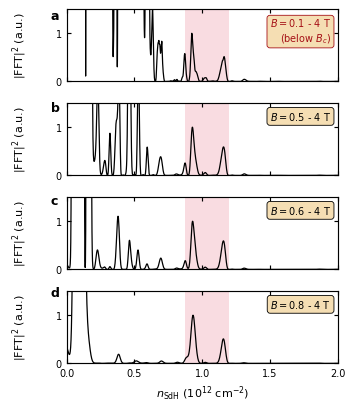

In [21]:
update_rc_params('paper')

LF_TARGET = 0.56
LF_CUTS   = [0.1, 0.5, 0.6, 0.8]          # first panel is below B_c
LF_BC     = 0.45                            # critical field of SC
LF_BMAX   = 4.0
LF_BG     = (detrend_butterworth, {'cutoff':  None, 'order': 4})
LF_PAD    = 4
LF_TONES  = (0.87, 1.2)
LF_XLIM   = (0, 2.0)
LF_H_OVER_E = 41.36


class StitchedLf(Lf_analysis):
    """Lf_analysis backed by the stitched fan instead of a single file."""
    def __init__(self, density, B, Rxx):
        self.density = np.asarray(density, float)
        self.B_raw = np.asarray(B, float)
        self.Rxx_raw = np.asarray(Rxx, float)
        self.displacement = None


dens_s, B_s, Rxx_s = zf_map()
keep = B_s <= LF_BMAX
lf_analyzer = StitchedLf(dens_s, B_s[keep], Rxx_s[keep])
n_val = lf_analyzer.density[np.argmin(np.abs(lf_analyzer.density - LF_TARGET))]

nrows = len(LF_CUTS)
fig, axes = plt.subplots(nrows, 1, figsize=(3.5, 4.6), sharex=True)
label_spacer = 0.045
bg_method, bg_params = LF_BG

for i, (blo, ax) in enumerate(zip(LF_CUTS, axes)):
    below_bc = blo < LF_BC
    psd, freq = lf_analyzer.get_fft_line(LF_TARGET, bg_method, bg_params,
                                         LF_PAD, blims=(blo, LF_BMAX))
    n_sdh = freq*n_val
    power = np.abs(psd)**2
    band = (n_sdh > 0.8) & (n_sdh < LF_XLIM[1])
    power = power/power[band].max()

    L = 1/blo - 1/LF_BMAX
    lim3 = 3/L/LF_H_OVER_E                       # three-cycle resolution limit

    ax.axvspan(*LF_TONES, color='crimson', alpha=0.15, lw=0, zorder=0)
    ax.plot(n_sdh, power, lw=0.9, color='k', zorder=2)

    ax.set_xlim(*LF_XLIM)
    ax.set_ylim(0, 1.5)
    ax.set_ylabel(r'$|\mathrm{FFT}|^2$ (a.u.)')
    ax.set_yticks([0, 1])
    ax.yaxis.set_label_coords(-0.14, 0.5)
    ax.tick_params(direction='in', top=True, right=True)

    txt = rf'$B = {blo:.1f}$ - ${LF_BMAX:.0f}$ T'
    if below_bc:
        txt += '\n' + r'(below $B_c$)'
    ax.annotate(txt, (0.975, 0.90), xycoords='axes fraction',
                ha='right', va='top', fontsize=7, linespacing=1.3,
                color='#A50F15' if below_bc else 'k',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='wheat',
                          edgecolor='#A50F15' if below_bc else 'k',
                          linewidth=0.6))

    if i == nrows - 1:
        ax.set_xlabel(r'$n_{\mathrm{SdH}}$ ($10^{12}$ cm$^{-2}$)')
    else:
        ax.tick_params(labelbottom=False)

    bm = (blo < lf_analyzer.B_raw) & (lf_analyzer.B_raw < LF_BMAX)
    dinv = np.abs(np.diff(1/lf_analyzer.B_raw[bm]))
    print(f"B_min={blo:.2f} T | L={L:.3f} T^-1 | npts={bm.sum()} | "
          f"3-cycle limit n_SdH={lim3:.3f} | "
          f"Nyquist n_SdH={1/(2*dinv.max())/LF_H_OVER_E:.2f}")

fig.canvas.draw()
for letter, ax in zip('abcd', axes):
    pos = ax.get_position()
    fig.text(pos.x0 - label_spacer, pos.y1, letter, fontweight='bold',
             va='top')

fig.subplots_adjust(hspace=0.30)
fig.savefig("figS_lowfield_cutoff.pdf", dpi=600, bbox_inches='tight',
            pad_inches=0.02, transparent=False)

update_rc_params('talk')

# Raw data

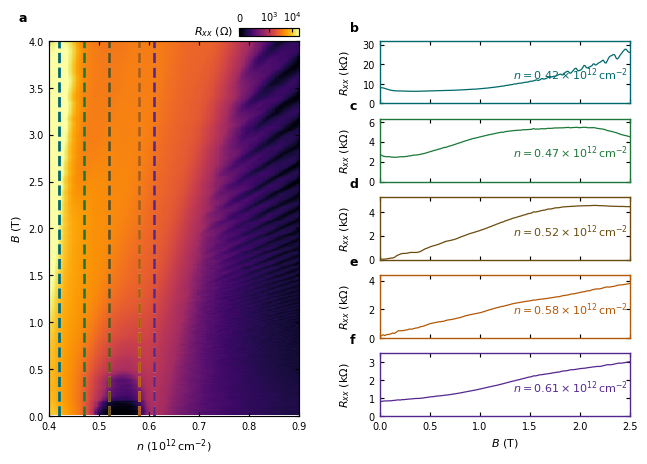

In [35]:
update_rc_params('paper')

# ── Global colorbar geometry ──────────────────────────────────────────────────
cb_width = 0.08          # colorbar width in figure fraction
cb_height_inches = 0.08  # colorbar height in physical inches (fixed across fig sizes)
# ─────────────────────────────────────────────────────────────────────────────

RX_TARGETS = [0.42, 0.47, 0.52, 0.58, 0.61]
RX_ZOOM    = (0, 2.5)                  # field range for both the fan and the cuts
rx_colors  = ['#00696B', '#1B7837', '#6B4C0F', '#B35806', '#54278F']

nrows = len(RX_TARGETS)
fig = plt.figure(figsize=(7.5, 5.0))
gs = GridSpec(nrows, 2, figure=fig, width_ratios=[1, 1],
              wspace=0.32, hspace=0.25, top=0.86)
ax_fan = fig.add_subplot(gs[:, 0])
axes_cut = [fig.add_subplot(gs[i, 1]) for i in range(nrows)]

cb_height_frac = cb_height_inches / fig.get_size_inches()[1]
label_spacer = 0.04

################ Panel a: raw Landau fan ##################
dens, B, Rxx_map = zf_map()
norm = colors.SymLogNorm(linthresh=750, vmin=0, vmax=20e3)
#norm = colors.Normalize(vmin=0, vmax=5e3)
plot = ax_fan.pcolormesh(dens, B, Rxx_map, norm=norm, cmap='inferno',
                         rasterized=True, lw=0)
ax_fan.set_xlabel(r'$n$ $\left(10^{12}\,\mathrm{cm}^{-2}\right)$')
ax_fan.set_ylabel(r'$B$ (T)')
ax_fan.set_xlim(0.40, 0.9)
ax_fan.set_ylim(0, 4)

for n, c in zip(RX_TARGETS, rx_colors):
    ax_fan.axvline(n, color=c, ls='--', lw=2,
                   path_effects=[pe.Stroke(linewidth=1.8, foreground='w'),
                                 pe.Normal()])

fig.canvas.draw()
pos = ax_fan.get_position()
fig.text(pos.x0 - label_spacer, pos.y1 + label_spacer, "a", fontweight='bold')

cax = fig.add_axes([pos.x1 - cb_width, pos.y1 + 0.01, cb_width, cb_height_frac])
cb = plt.colorbar(plot, cax=cax, ticks=[0, 1e3, 1e4],
                  orientation='horizontal')
cb.ax.annotate(r'$R_{xx}$ ($\Omega$)', xy=(-0.10, 0.5), xycoords='axes fraction',
               ha='right', va='center', fontsize=plt.rcParams['axes.labelsize'])
cb.ax.xaxis.set_ticks_position('top')
cb.ax.xaxis.set_label_position('top')
cb.set_ticklabels(['$0$', '$10^3$', '$10^4$'])

################ Panels b-f: raw linecuts ##################
letters = ['b', 'c', 'd', 'e', 'f']
for i, (n, color, ax) in enumerate(zip(RX_TARGETS, rx_colors, axes_cut)):
    B_cut, Rxx = zf_cut(n)
    m = (RX_ZOOM[0] <= B_cut) & (B_cut <= RX_ZOOM[1])
    y = Rxx[m]*1e-3

    ax.plot(B_cut[m], y, lw=0.9, color=color)
    ax.set_xlim(*RX_ZOOM)
    ax.set_ylim(0, 1.15*np.max(y))
    ax.set_ylabel(r'$R_{xx}$ (k$\Omega$)')
    ax.locator_params(axis='y', nbins=4, steps=[1, 2, 5, 10])
    ax.yaxis.set_label_coords(-0.11, 0.5)

    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(1.0)

    lbl = rf'$n = {n:.2f} \times 10^{{12}}\,\mathrm{{cm}}^{{-2}}$'
    ax.annotate(lbl, (0.99, 0.6), xycoords='axes fraction', ha='right',
                va='top', color=color, fontsize=8)

    if i == nrows - 1:
        ax.set_xlabel(r'$B$ (T)')
    else:
        ax.tick_params(labelbottom=False)

fig.canvas.draw()
for letter, ax in zip(letters, axes_cut):
    pos = ax.get_position()
    fig.text(pos.x0 - label_spacer, pos.y1 + 0.5*label_spacer, letter,
             fontweight='bold')

plt.rcParams['svg.fonttype'] = 'none'
fig.savefig("figS_fan_and_raw_cuts.pdf", dpi=600, bbox_inches='tight',
            pad_inches=0.02, transparent=False)

update_rc_params('talk')